In [5]:
import numpy as np
from datetime import date, timedelta

start_date = date(2026, 6, 1)
end_date = date(2026, 6, 7)


In [6]:
ssts = []
for i in range((end_date - start_date).days):
    current_date = start_date + timedelta(days=i)
    for day in (0, 12):
        day_str = str(day).zfill(2)
        sst_example = np.load(f"../data/{current_date.strftime('%Y/%m/%d')}/{day_str}/sst.npy", allow_pickle=True)
        ssts.append(sst_example.astype(np.float64))

sst_full = np.stack(ssts, axis=-1)

In [7]:
# Mirrors the ocean-mask construction in src/weather/model.py's
# `_mask_and_stack` (used by WeatherModel.fit): a cell counts as "ocean"
# only if it is non-NaN across every training snapshot, for every modeled
# variable (here just `sst`). Unlike the production pipeline — which then
# ravels (lat, lon) into a single `ocean_cell` Tucker mode and drops land
# cells from the tensor entirely — this notebook keeps `sst_full`'s 3D
# (lat, lon, time) shape so lat and lon stay separate Tucker modes to
# explore. Land/ice cells are instead flagged via a mask passed to
# `partial_tucker(mask=...)`, which iteratively imputes them from the
# current low-rank reconstruction instead of contributing raw NaN (or an
# arbitrary sentinel like -9999) to the decomposition.
ocean_mask = ~np.isnan(sst_full).any(axis=-1)  # (1121, 2880) bool

# partial_tucker's `mask` must match `tensor`'s shape, with 1.0 for
# observed entries and 0.0 for entries to impute.
_mask = np.broadcast_to(ocean_mask[:, :, None], sst_full.shape).astype(np.float64)

# The masked HOI loop overwrites entries where tucker_mask == 0 on its
# first iteration, but tensorly computes the tensor's norm once up front
# using these raw values — NaN would poison that norm, and a sentinel like
# -9999 would inflate it. 0.0 is a neutral placeholder immediately
# replaced by the reconstruction-based imputation.
sst_filled = np.where(ocean_mask[:, :, None], sst_full, 0.0)

# Understand DMD, without flattening the spatial grid

Same caveats as `01_understand_tucker_decomposition.ipynb`: `sst_filled`
above already carries the ocean/land mask (land/ice zeroed, not dropped),
and every `(lat, lon)` snapshot below stays a genuine 2D array all the way
through — nothing here ever collapses `(lat, lon)` into a single flat cell
axis, the way classical DMD's textbook formulation normally does.

**Why that's normally a problem for DMD specifically.** Classical exact DMD
builds a data matrix by flattening each time snapshot into one long column
vector, stacks the columns side by side, and takes an SVD of that matrix.
For `sst_filled`'s `(1121, 2880)` grid, that column would be ~3.2 million
entries long — and more importantly, *forming it at all* means giving up
`(lat, lon)`'s separate axis structure, which is exactly the thing we're
avoiding here.

**The fix: the "method of snapshots".** When the state dimension (here,
~3.2M grid cells) vastly exceeds the number of snapshots (12, loaded
above), DMD/POD have a standard trick for exactly this regime: instead of
computing the SVD of the huge `(state, time)` matrix directly, compute the
eigendecomposition of the *tiny* `(time, time)` Gram matrix of pairwise
snapshot inner products instead — the two share the same nonzero
eigenvalues, and the expensive-looking basis can be recovered from the
snapshots themselves afterward. The key property we want: a Frobenius inner
product between two `(lat, lon)` snapshots, `sum(Xi * Xj)`, is *exactly*
the same number whether you flatten first or not — so every step below
uses `einsum`/broadcasting to contract over the spatial axes directly,
without ever materializing a flattened array. This isn't an approximation
of classical DMD; it's an algebraically exact way to compute it that
happens to never need to flatten anything, and it also skips Tucker
entirely, as requested — this is DMD on the raw (masked) data, not on a
Tucker core.

Also skipped, deliberately, for this understanding-only exercise: fitting
initial amplitudes / simulating forward in time. The goal here is seeing
what the DMD modes and eigenvalues *are*, the same way notebook 01 showed
what the Tucker factor matrices are — not building the sampling pipeline,
which comes later.

In [8]:
X = sst_filled[:, :, :-1]  # snapshots 0..T-2, shape (lat, lon, T-1)
X_prime = sst_filled[:, :, 1:]  # snapshots 1..T-1, one step ahead, same shape

n_snapshots = X.shape[-1]
print(f"X shape: {X.shape} — spatial axes kept separate, never merged into one axis")

X shape: (1121, 2880, 11) — spatial axes kept separate, never merged into one axis


In [9]:
# Frobenius inner product between every pair of snapshots in X, contracted
# directly over the spatial axes (0, 1) via einsum — mathematically
# identical to flattening each snapshot to a vector and computing
# X_flat.T @ X_flat, but the (lat, lon) axes are never merged into a
# stored intermediate array at any point. Land cells are exactly 0 at
# every snapshot (sst_filled, masked above), so they contribute 0 to every
# inner product below and never bias the fit — this is how the land mask
# propagates through here, in place of Tucker's iterative imputation.
gram = np.einsum("ijk,ijl->kl", X, X)  # (T-1, T-1) — tiny, independent of grid size
print(f"gram shape: {gram.shape}")

gram shape: (11, 11)


In [10]:
# gram is symmetric PSD: gram = V @ diag(eigvals) @ V.T, and those
# eigenvalues are exactly sigma**2 from the (never-formed) flattened X's
# SVD X_flat = U @ diag(sigma) @ V.T — the "method of snapshots" identity.
eigvals, V = np.linalg.eigh(gram)  # ascending order
order = np.argsort(eigvals)[::-1]
eigvals, V = eigvals[order], V[:, order]

eigvals = np.clip(eigvals, 0.0, None)  # guard tiny negative numerical noise
sigma = np.sqrt(eigvals)

rank = int(np.sum(sigma > 1e-8 * sigma[0]))  # drop numerically-zero singular values
sigma, V = sigma[:rank], V[:, :rank]
print(f"retained rank: {rank} of {n_snapshots} snapshots")

retained rank: 11 of 11 snapshots


In [11]:
# U's columns are the left singular "vectors" of the never-formed flattened
# X — each is itself a (lat, lon) spatial pattern, recovered as a weighted
# sum of the snapshots in X (U = X_flat @ V @ diag(1/sigma), computed here
# without ever flattening X). This is the direct DMD analog of notebook
# 01's Tucker factor-matrix columns: an eigenvector spatial basis — but
# derived from *temporal* correlation between snapshots (the Gram matrix),
# not from HOSVD's per-mode spatial unfolding.
U = np.einsum("ijk,kr->ijr", X, V) / sigma[None, None, :]  # (lat, lon, rank)
print(f"U shape: {U.shape}")

U shape: (1121, 2880, 11)


In [12]:
# Project every X' snapshot onto the U basis — again via einsum over the
# spatial axes, never flattened — then combine with V/sigma to get the
# reduced-order operator A_tilde = U.T @ X'_flat @ V @ diag(1/sigma).
# From here on everything is small (rank x rank) linear algebra on
# coefficients, not on the spatial grid.
U_T_Xprime = np.einsum("ijr,ijk->rk", U, X_prime)  # (rank, T-1)
A_tilde = U_T_Xprime @ V @ np.diag(1.0 / sigma)  # (rank, rank)
print(f"A_tilde shape: {A_tilde.shape}")

A_tilde shape: (11, 11)


In [13]:
dmd_eigvals, W = np.linalg.eig(A_tilde)  # complex in general — DMD's discrete-time eigenvalues

# "Exact" DMD modes (Tu et al. 2014): Phi = X'_flat @ V @ diag(1/sigma) @ W.
# Build the X'-side basis the same way U was built from X, then combine
# with W — still purely a coefficient-space combination at the last step,
# so Phi's (lat, lon) spatial axes are, once again, never flattened.
Phi_basis = np.einsum("ijk,kr->ijr", X_prime, V) / sigma[None, None, :]  # (lat, lon, rank)
Phi = np.einsum("ijr,rk->ijk", Phi_basis.astype(complex), W)  # (lat, lon, rank) complex — the DMD modes

dt_seconds = 12 * 3600.0  # snapshots are 12-hourly (00Z/12Z), per the loading cell above
continuous_rate = np.log(dmd_eigvals) / dt_seconds  # 1/s; real part = growth/decay, imag = angular frequency

for k in range(rank):
    growth_per_day = continuous_rate[k].real * 86400
    period_hours = (
        abs(2 * np.pi / continuous_rate[k].imag / 3600) if continuous_rate[k].imag != 0 else float("inf")
    )
    print(
        f"mode {k:2d}: |lambda|={abs(dmd_eigvals[k]):.4f}  "
        f"growth={growth_per_day:+7.3f}/day  period={period_hours:8.1f} h"
    )

mode  0: |lambda|=0.9993  growth= -0.001/day  period=     inf h
mode  1: |lambda|=0.8107  growth= -0.420/day  period=     inf h
mode  2: |lambda|=0.7752  growth= -0.509/day  period=   115.1 h
mode  3: |lambda|=0.7752  growth= -0.509/day  period=   115.1 h
mode  4: |lambda|=0.7534  growth= -0.566/day  period=    59.4 h
mode  5: |lambda|=0.7534  growth= -0.566/day  period=    59.4 h
mode  6: |lambda|=0.9483  growth= -0.106/day  period=    24.0 h
mode  7: |lambda|=0.7976  growth= -0.452/day  period=    30.4 h
mode  8: |lambda|=0.7976  growth= -0.452/day  period=    30.4 h
mode  9: |lambda|=0.7607  growth= -0.547/day  period=    40.8 h
mode 10: |lambda|=0.7607  growth= -0.547/day  period=    40.8 h


## Visualizing the result

Each DMD mode `Phi[:, :, k]` is a full `(lat, lon)` spatial pattern — same
as `U`'s columns — paired with one complex eigenvalue `dmd_eigvals[k]`
describing how that pattern grows/decays and oscillates in time. Plotting
a few modes as maps is the DMD analog of notebook 01's factor-matrix-column
plots; plotting the eigenvalues on the complex plane shows growth/decay
(distance from the unit circle) and oscillation frequency (angle) at a
glance.

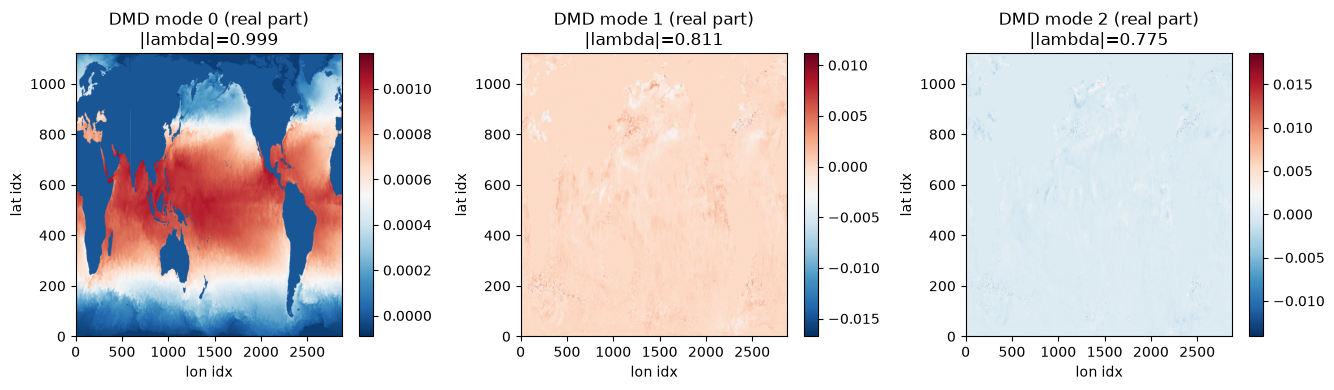

In [14]:
import matplotlib.pyplot as plt

n_show = min(3, rank)
fig, axes = plt.subplots(1, n_show, figsize=(4.5 * n_show, 4))
axes = np.atleast_1d(axes)
for k, ax in enumerate(axes):
    im = ax.imshow(Phi[:, :, k].real, origin="lower", aspect="auto", cmap="RdBu_r")
    fig.colorbar(im, ax=ax)
    ax.set_title(f"DMD mode {k} (real part)\n|lambda|={abs(dmd_eigvals[k]):.3f}")
    ax.set_xlabel("lon idx")
    ax.set_ylabel("lat idx")
fig.tight_layout()

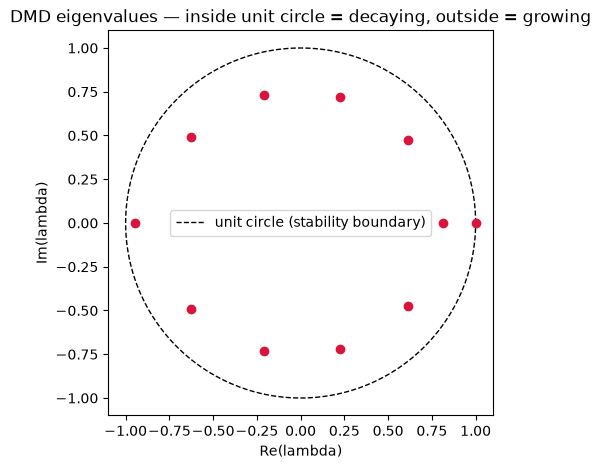

In [15]:
theta = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(np.cos(theta), np.sin(theta), "k--", linewidth=1, label="unit circle (stability boundary)")
ax.scatter(dmd_eigvals.real, dmd_eigvals.imag, c="crimson", zorder=3)
ax.set_xlabel("Re(lambda)")
ax.set_ylabel("Im(lambda)")
ax.set_title("DMD eigenvalues — inside unit circle = decaying, outside = growing")
ax.set_aspect("equal")
ax.legend()

## Notes and caveats

- This ran DMD directly on the masked raw `sst` tensor — no Tucker step
  first, per the request. That's a real difference from
  `docs/dynamic_mode_decomposition.md`'s prescribed pipeline, where DMD
  consumes a much smaller, already-compressed per-variable Tucker core;
  here, DMD's own "method of snapshots" trick is doing double duty as the
  dimensionality reduction, since the number of snapshots (12) is what
  bounds the rank, not an explicit Tucker rank choice.
- `docs/dynamic_mode_decomposition.md` §4.2 flags an open "state-vectorization
  tension" — whether DMD should vectorize each time-slice's state or use a
  tensor-native formulation that never does. This notebook is a concrete
  instance of the tensor-native side of that question: the method-of-snapshots
  formulation used above never flattens `(lat, lon)`, for any grid size, as
  long as the number of snapshots stays the bottleneck dimension. It stops
  being free once the *rank kept* needs to exceed the snapshot count (e.g.
  after concatenating multiple variables' coefficients, per
  `docs/correlated_variables.md`'s joint-group proposal) — at that point some
  form of the ordinary flattened SVD becomes unavoidable.
- Twelve snapshots and one variable (`sst`) is enough to see what a DMD
  mode and eigenvalue *are*, not enough to say anything physically
  meaningful about growth rates or periods here — that needs a real
  training window and is exactly the "pipeline" work this notebook is
  explicitly not trying to do yet.